# Predicting Machine Failures (Predictive Maintenance)

Unplanned machine downtime is expensive. If we can predict a failure **before** it happens, maintenance can be scheduled instead of reacting to breakdowns.

**Goal:** Predict whether a milling machine will fail, based on its sensor readings, and find out which factors drive failures.

**Data:** [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601) (UCI, CC BY 4.0): 10,000 records with air and process temperature, rotational speed, torque, tool wear and product quality type (L / M / H).

**Outline**
1. Explore the data
2. Engineer features from the physics of the machine
3. Train and compare models (handling a strongly imbalanced target)
4. Tune the decision threshold
5. Explain what drives failures

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from pm.data import FAILURE_MODES, load
from pm.features import BASE_FEATURES, CATEGORICAL_FEATURES, ENGINEERED_FEATURES, add_features

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.3f}".format)

Matplotlib is building the font cache; this may take a moment.


## 1. Explore the data

In [2]:
df = load()
print(df.shape)
df.head()

(10000, 14)


,udi,product_id,type,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.000,5000.500,2886.896,1.000,2500.750,5000.500,7500.250,10000.000
air_temp_k,10000.000,300.005,2.000,295.300,298.300,300.100,301.500,304.500
process_temp_k,10000.000,310.006,1.484,305.700,308.800,310.100,311.100,313.800
rpm,10000.000,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000
torque_nm,10000.000,39.987,9.969,3.800,33.200,40.100,46.800,76.600
tool_wear_min,10000.000,107.951,63.654,0.000,53.000,108.000,162.000,253.000
failure,10000.000,0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,10000.000,0.005,0.068,0.000,0.000,0.000,0.000,1.000
HDF,10000.000,0.011,0.107,0.000,0.000,0.000,0.000,1.000
PWF,10000.000,0.009,0.097,0.000,0.000,0.000,0.000,1.000


In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values: 0
Duplicate rows: 0


### How often do machines fail?
This is the most important question before modelling: if failures are rare, **accuracy is a misleading metric**. A model that always says "no failure" would already look very accurate.

Failure rate: 3.39%  (339 of 10,000 records)
Accuracy of always predicting 'no failure': 96.61%


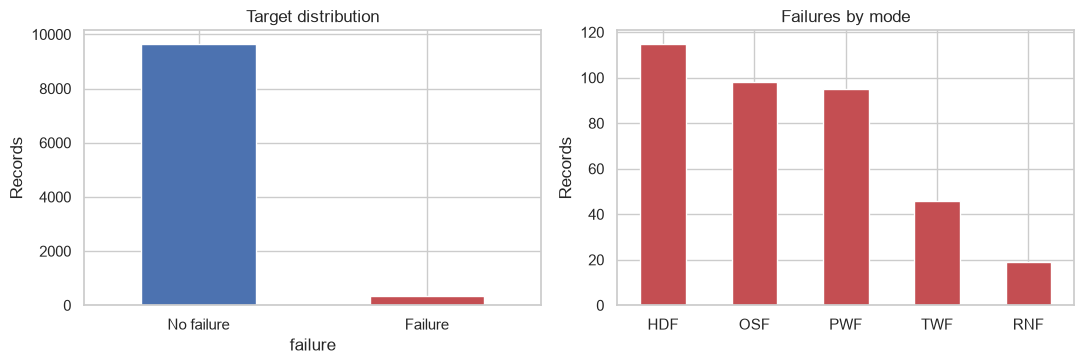

In [5]:
rate = df["failure"].mean()
print(f"Failure rate: {rate:.2%}  ({df['failure'].sum()} of {len(df):,} records)")
print(f"Accuracy of always predicting 'no failure': {1 - rate:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
df["failure"].map({0: "No failure", 1: "Failure"}).value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0)
axes[0].set_title("Target distribution")
axes[0].set_ylabel("Records")
df[FAILURE_MODES].sum().sort_values(ascending=False).plot.bar(ax=axes[1], color="#C44E52", rot=0)
axes[1].set_title("Failures by mode")
axes[1].set_ylabel("Records")
plt.tight_layout()
plt.show()

Failure modes: **TWF** tool wear, **HDF** heat dissipation, **PWF** power, **OSF** overstrain, **RNF** random.

These flags describe *which kind* of failure happened, so they are only known after the fact. Using them as inputs would be **data leakage**, so they are excluded from the model.

### Sensor readings: failure vs. no failure

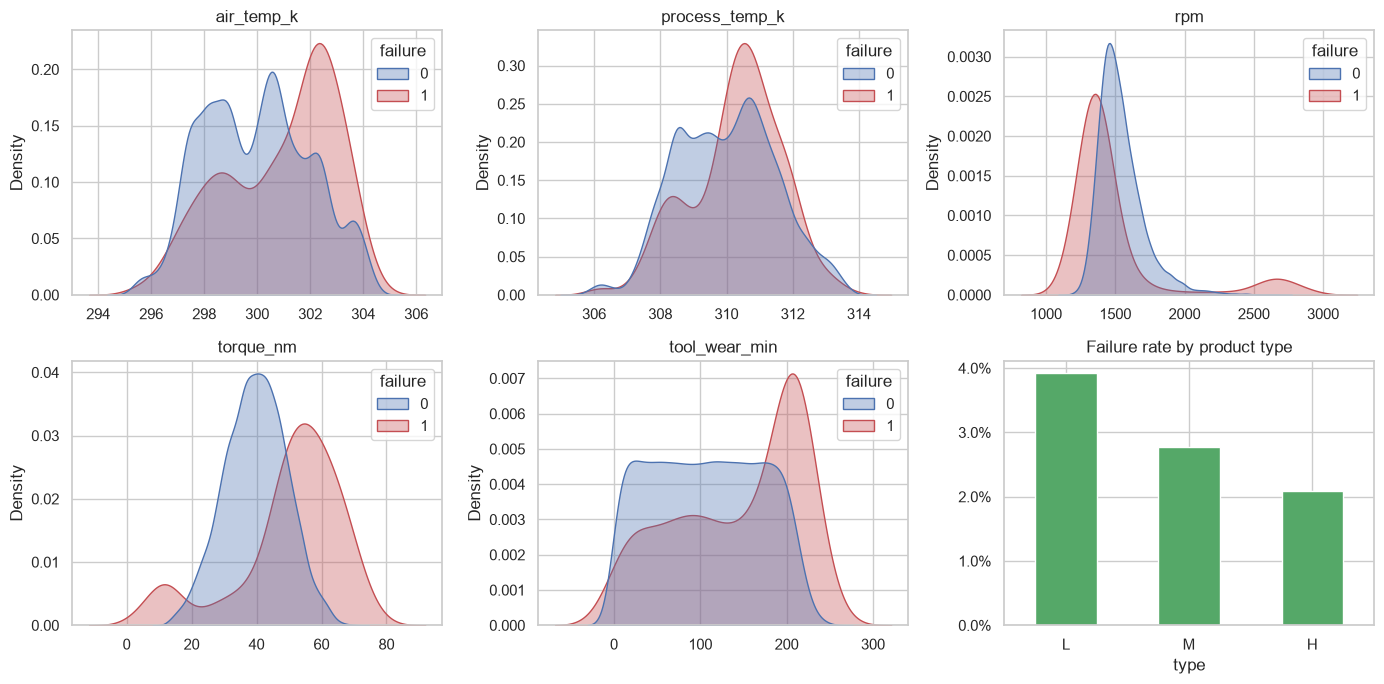

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, BASE_FEATURES):
    sns.kdeplot(data=df, x=col, hue="failure", common_norm=False, fill=True, alpha=0.35, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
    ax.set_xlabel("")
rates = df.groupby("type", observed=True)["failure"].mean()
rates.plot.bar(ax=axes[1, 2], color="#55A868", rot=0)
axes[1, 2].set_title("Failure rate by product type")
axes[1, 2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
plt.tight_layout()
plt.show()

**Observations**
- Failures are concentrated at **high tool wear** and at **extreme torque** values (both very low and very high).
- Rotational speed and torque are strongly linked, so their *combination* matters more than each one alone.
- The temperatures alone separate the classes only weakly.

## 2. Feature engineering
Instead of only using raw sensors, we add three features that follow from how a milling machine works:

| Feature | Formula | Why |
|---|---|---|
| `temp_diff_k` | process temp − air temp | small difference → heat can't dissipate |
| `power_w` | torque × rpm × 2π / 60 | too little or too much power stresses the machine |
| `strain` | tool wear × torque | worn tool under high load → overstrain |

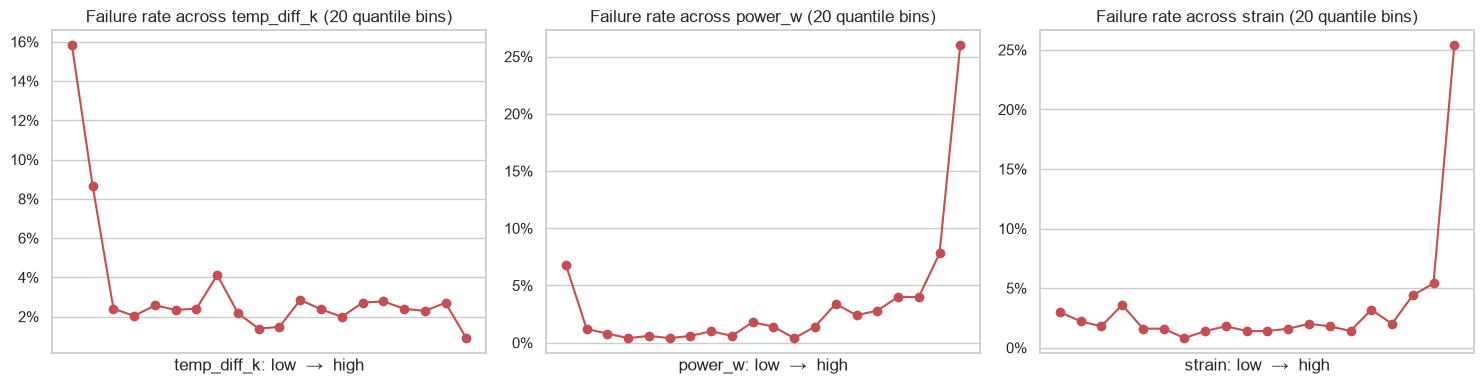

In [7]:
df = add_features(df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ENGINEERED_FEATURES):
    binned = pd.qcut(df[col], q=20, duplicates="drop")
    curve = df.groupby(binned, observed=True)["failure"].mean()
    ax.plot(range(len(curve)), curve.values, marker="o", color="#C44E52")
    ax.set_title(f"Failure rate across {col} (20 quantile bins)")
    ax.set_xlabel(f"{col}: low  →  high")
    ax.set_xticks([])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.savefig(FIG_DIR / "engineered_features.png", dpi=150, bbox_inches="tight")
plt.show()

Each engineered feature shows a clear pattern: the failure rate jumps at the **low end of `temp_diff_k`**, at **both ends of `power_w`** and at the **high end of `strain`**. These are exactly the kinds of thresholds a tree-based model can pick up easily.

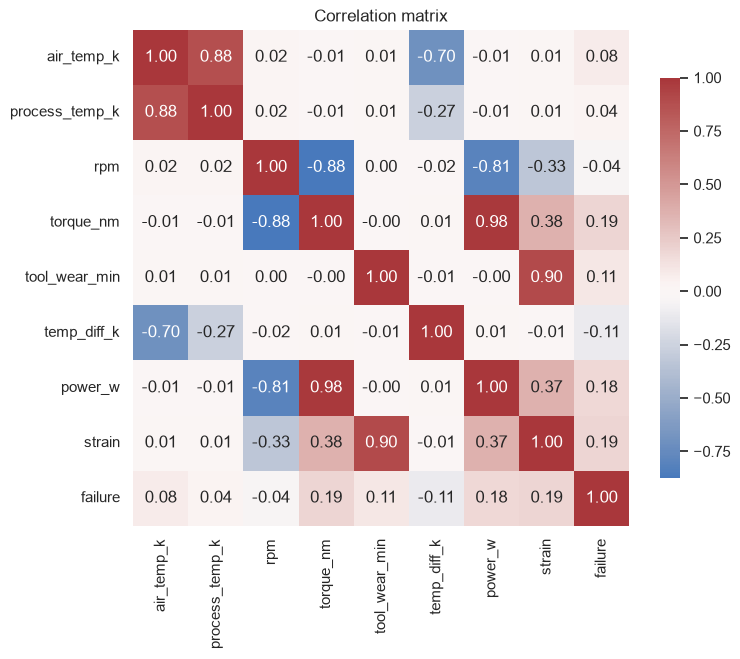

In [8]:
corr = df[BASE_FEATURES + ENGINEERED_FEATURES + ["failure"]].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix")
plt.show()

Note that the linear correlation of each feature with `failure` is small. That doesn't mean the features are useless: the relationships are **non-linear** (e.g. failures at *both* ends of `power_w`), which a correlation coefficient cannot capture.

## 3. Modelling

**Setup**
- Inputs: sensor readings, engineered features and product type. Excluded: IDs and the failure-mode flags (leakage).
- **Stratified** train/test split (80/20), so both sets keep the same failure rate.
- The test set is used **only once** at the end. All tuning happens with cross-validation on the training set.

**Metrics**, chosen for an imbalanced target:
- **PR-AUC** (average precision): how well the model ranks failures above normal records, independent of a threshold. A random model scores roughly the failure rate.
- **Recall**: share of real failures we catch. Missing a failure means unplanned downtime.
- **Precision**: share of alarms that are real. Low precision means unnecessary inspections.

In [9]:
X = df[BASE_FEATURES + ENGINEERED_FEATURES + CATEGORICAL_FEATURES]
y = df["failure"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} rows, {y_train.mean():.2%} failures")
print(f"Test:  {len(X_test):,} rows, {y_test.mean():.2%} failures")


def make_pipeline(model, numeric):
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])
    return Pipeline([("pre", pre), ("model", model)])


models = {
    "Baseline (always 'no failure')": make_pipeline(DummyClassifier(strategy="prior"), BASE_FEATURES),
    "Logistic Regression (raw sensors)": make_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000), BASE_FEATURES
    ),
    "Logistic Regression (+ engineered)": make_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000), BASE_FEATURES + ENGINEERED_FEATURES
    ),
    "Random Forest (+ engineered)": make_pipeline(
        RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
        ),
        BASE_FEATURES + ENGINEERED_FEATURES,
    ),
}

rows, test_scores = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_scores[name] = proba
    rows.append({
        "model": name,
        "PR-AUC": average_precision_score(y_test, proba),
        "recall": recall_score(y_test, pred, zero_division=0),
        "precision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

results = pd.DataFrame(rows).set_index("model")
results

Train: 8,000 rows, 3.39% failures
Test:  2,000 rows, 3.40% failures


,PR-AUC,recall,precision,F1
model,,,,
Baseline (always 'no failure'),0.034,0.000,0.000,0.000
Logistic Regression (raw sensors),0.382,0.824,0.142,0.242
Logistic Regression (+ engineered),0.430,0.882,0.179,0.298
Random Forest (+ engineered),0.874,0.809,0.948,0.873


**Reading the table** (threshold 0.5)
- The baseline confirms that PR-AUC ≈ failure rate means "no skill".
- Logistic regression with `class_weight="balanced"` catches many failures but raises many false alarms: a linear model can't express "failure at *both* ends of power".
- The engineered features help the linear model, but the **random forest** can learn the non-linear thresholds directly and is the clear winner on PR-AUC.

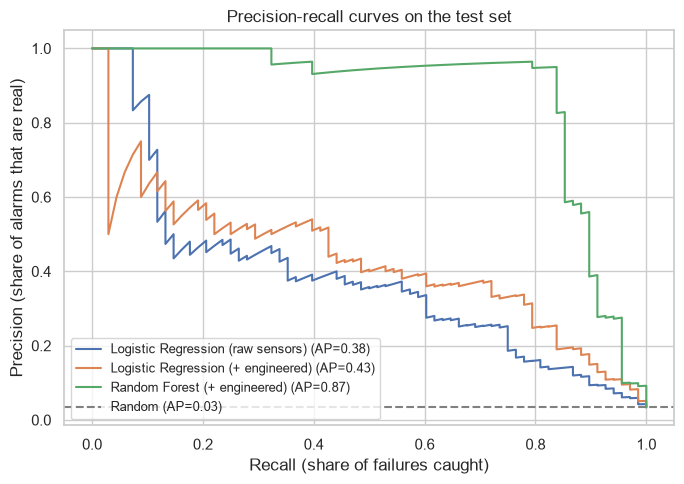

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in test_scores.items():
    if name.startswith("Baseline"):
        continue
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, proba):.2f})")
ax.axhline(y_test.mean(), color="grey", ls="--", label=f"Random (AP={y_test.mean():.2f})")
ax.set_xlabel("Recall (share of failures caught)")
ax.set_ylabel("Precision (share of alarms that are real)")
ax.set_title("Precision-recall curves on the test set")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Choosing the decision threshold
The default threshold of 0.5 is arbitrary. In maintenance, **missing a failure usually costs more than an extra inspection**, so we pick the threshold deliberately.

To avoid tuning on the test set, we use **out-of-fold predictions** from 5-fold cross-validation on the training set and pick the threshold that maximizes F1. Then we apply it to the test set once.

In [11]:
best_name = "Random Forest (+ engineered)"
best = models[best_name]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p, r, thresholds = precision_recall_curve(y_train, oof)
f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
threshold = float(thresholds[np.argmax(f1)])
print(f"Chosen threshold (max F1 in cross-validation): {threshold:.2f}")

proba_test = test_scores[best_name]
pred_test = (proba_test >= threshold).astype(int)
summary = pd.Series({
    "PR-AUC": average_precision_score(y_test, proba_test),
    "recall": recall_score(y_test, pred_test),
    "precision": precision_score(y_test, pred_test),
    "F1": f1_score(y_test, pred_test),
}, name=f"{best_name}, threshold {threshold:.2f}")
summary.to_frame().T

Chosen threshold (max F1 in cross-validation): 0.42


,PR-AUC,recall,precision,F1
"Random Forest (+ engineered), threshold 0.42",0.874,0.838,0.934,0.884


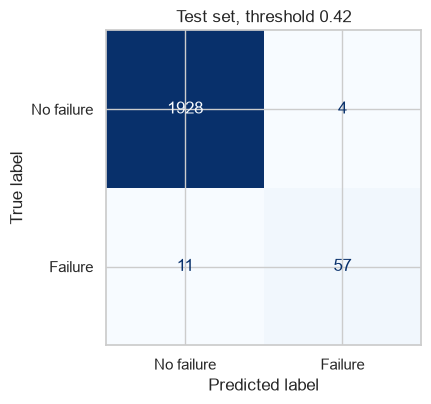

Caught 57 of 68 failures, with 4 false alarms among 1,932 normal records.


In [12]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["No failure", "Failure"], cmap="Blues", colorbar=False, ax=ax
)
ax.set_title(f"Test set, threshold {threshold:.2f}")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = pd.crosstab(y_test, pred_test).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values.ravel()
print(f"Caught {tp} of {tp + fn} failures, with {fp} false alarms among {tn + fp:,} normal records.")

## 5. What drives failures?
**Permutation importance** shuffles one feature at a time on the test set and measures how much PR-AUC drops. The bigger the drop, the more the model relies on that feature. Unlike the built-in tree importance, it is measured on unseen data.

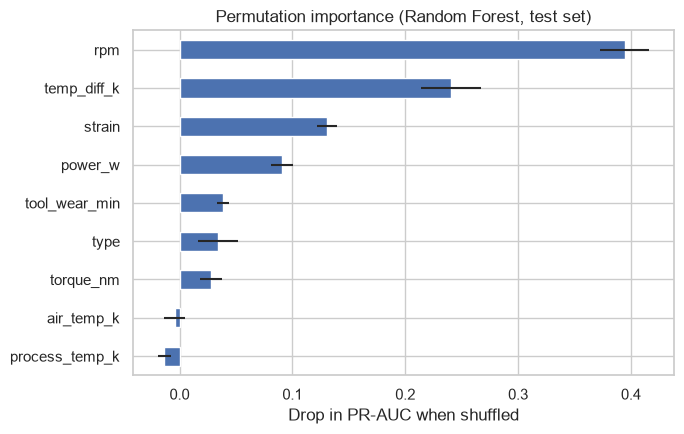

,importance
rpm,0.395
temp_diff_k,0.240
strain,0.131
power_w,0.091
tool_wear_min,0.038
type,0.034
torque_nm,0.028
air_temp_k,-0.004
process_temp_k,-0.013


In [13]:
imp = permutation_importance(
    best, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1
)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
importance.plot.barh(ax=ax, xerr=pd.Series(imp.importances_std, index=X_test.columns)[importance.index], color="#4C72B0")
ax.set_xlabel("Drop in PR-AUC when shuffled")
ax.set_title("Permutation importance (Random Forest, test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).to_frame("importance")

## 6. Summary

- Failures are rare (about 3% of records), so the model was evaluated with **PR-AUC, recall and precision** instead of accuracy.
- **Physics-based features** (power, strain, temperature difference) capture the failure mechanisms directly and make the patterns easy to learn.
- A **random forest** clearly beats logistic regression because the failure rules are non-linear (e.g. failures at *both* very low and very high power).
- The decision threshold was tuned with **cross-validation on the training data only**, so the test result is an honest estimate.

**Limitations and next steps**
- AI4I 2020 is a *synthetic* dataset modelled on real machines, so real sensor data will be noisier.
- The data are snapshots, not time series. With real data, trends over time (e.g. rising temperature) would be valuable features.
- Instead of maximizing F1, the threshold could be set from actual costs (cost of downtime vs. cost of an inspection).
- Try gradient boosting (e.g. LightGBM) and predict the **failure mode** as a multi-class problem.